<a href="https://colab.research.google.com/github/DHRUV812/Spotify-Popularity-Prediction/blob/main/spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spotify Track Popularity Prediction

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
RANDOM_STATE = 42

In [ ]:
pip install seaborn --quiet


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Load & Explore Data

In [ ]:
DATA_PATH = 'downloads/dataset 3.csv'

df = pd.read_csv(DATA_PATH, index_col=0)
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()

Shape: 114,000 rows × 20 columns


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
df.info()
print('\nMissing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000


## 2. Exploratory Data Analysis

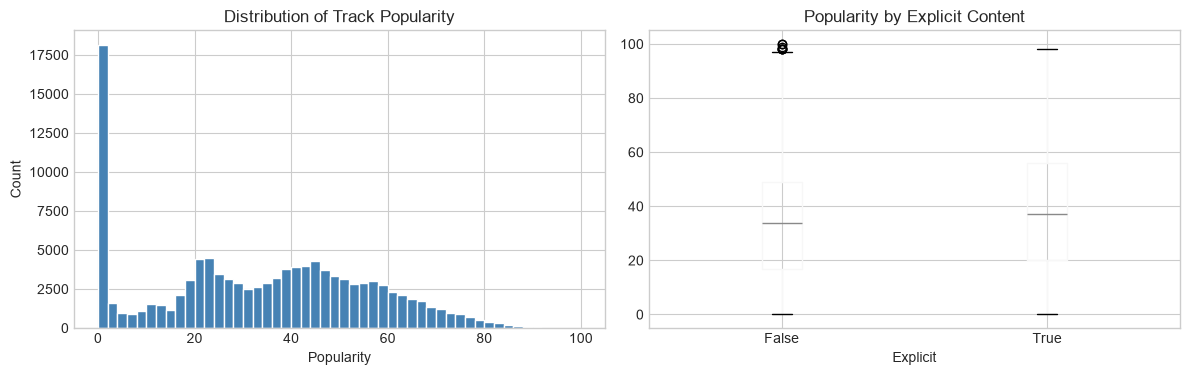

Mean popularity: 33.2
Median popularity: 35.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['popularity'], bins=50, edgecolor='white', color='steelblue')
axes[0].set_xlabel('Popularity')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Track Popularity')

df.boxplot(column='popularity', by='explicit', ax=axes[1])
axes[1].set_title('Popularity by Explicit Content')
axes[1].set_xlabel('Explicit')
plt.suptitle('')
plt.tight_layout()
plt.show()

print(f"Mean popularity: {df['popularity'].mean():.1f}")
print(f"Median popularity: {df['popularity'].median():.1f}")

In [ ]:
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]

corr_with_pop = df[audio_features + ['popularity']].corr()['popularity'].drop('popularity').sort_values(ascending=False)
print('Correlation with popularity:')
print(corr_with_pop.round(3))

Correlation with popularity:
loudness            0.050
danceability        0.035
tempo               0.013
energy              0.001
liveness           -0.005
acousticness       -0.025
valence            -0.041
speechiness        -0.045
instrumentalness   -0.095
Name: popularity, dtype: float64


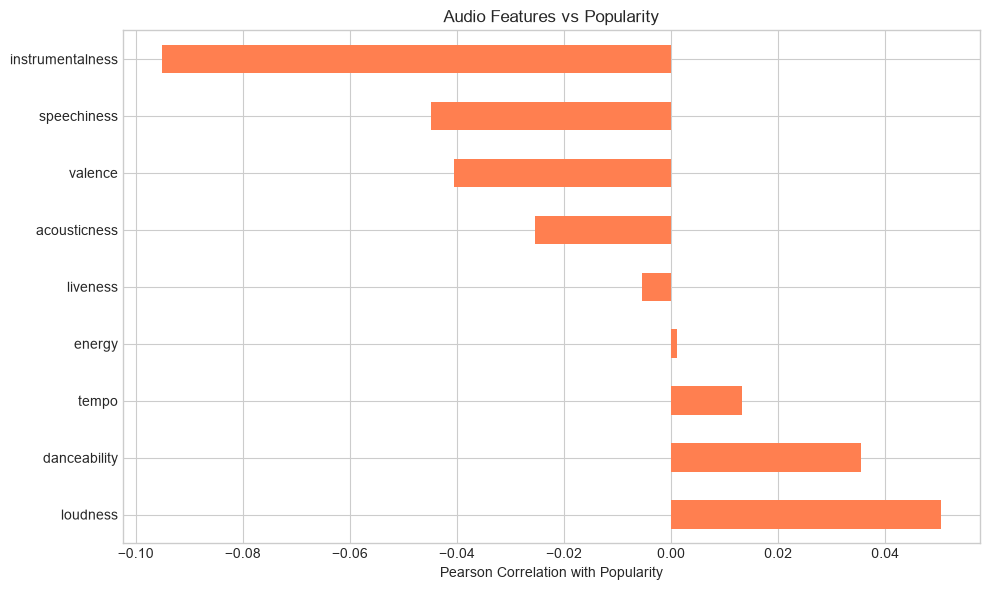

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
corr_with_pop.plot(kind='barh', ax=ax, color='coral')
ax.set_xlabel('Pearson Correlation with Popularity')
ax.set_title('Audio Features vs Popularity')
plt.tight_layout()
plt.show()

In [ ]:
genre_pop = df.groupby('track_genre')['popularity'].agg(['mean', 'count']).sort_values('mean', ascending=False)
print(f'Number of genres: {df["track_genre"].nunique()}')
print('\nTop 10 genres by mean popularity:')
print(genre_pop.head(10).round(1))
print('\nBottom 10 genres by mean popularity:')
print(genre_pop.tail(10).round(1))

Number of genres: 114

Top 10 genres by mean popularity:
             mean  count
track_genre             
pop-film     59.3   1000
k-pop        56.9   1000
chill        53.7   1000
sad          52.4   1000
grunge       49.6   1000
indian       49.5   1000
anime        48.8   1000
emo          48.1   1000
sertanejo    47.9   1000
pop          47.6   1000

Bottom 10 genres by mean popularity:
                mean  count
track_genre                
idm             15.8   1000
kids            14.9   1000
grindcore       14.6   1000
jazz            13.6   1000
classical       13.1   1000
chicago-house   12.3   1000
detroit-techno  11.2   1000
latin            8.3   1000
romance          3.2   1000
iranian          2.2   1000


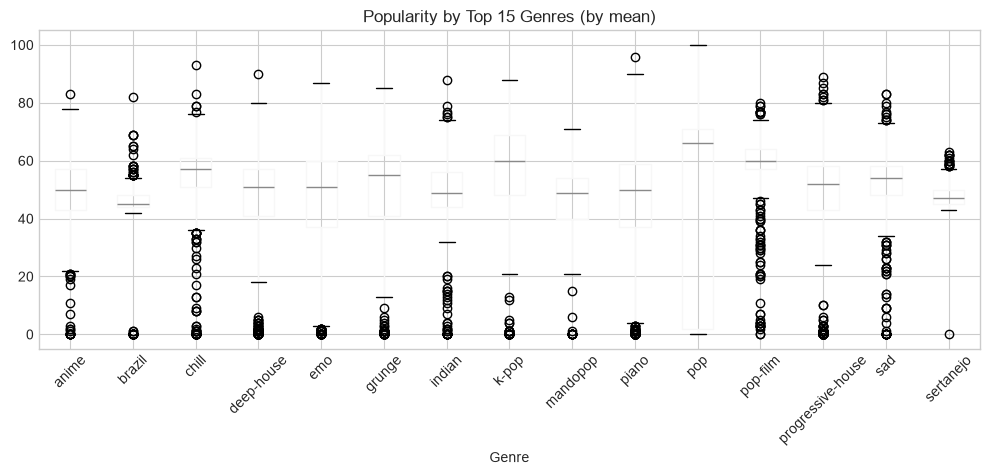

In [ ]:
top_genres = genre_pop.head(15).index
fig, ax = plt.subplots(figsize=(10, 5))
df[df['track_genre'].isin(top_genres)].boxplot(
    column='popularity', by='track_genre', ax=ax, rot=45
)
ax.set_title('Popularity by Top 15 Genres (by mean)')
ax.set_xlabel('Genre')
plt.suptitle('')
plt.tight_layout()
plt.show()

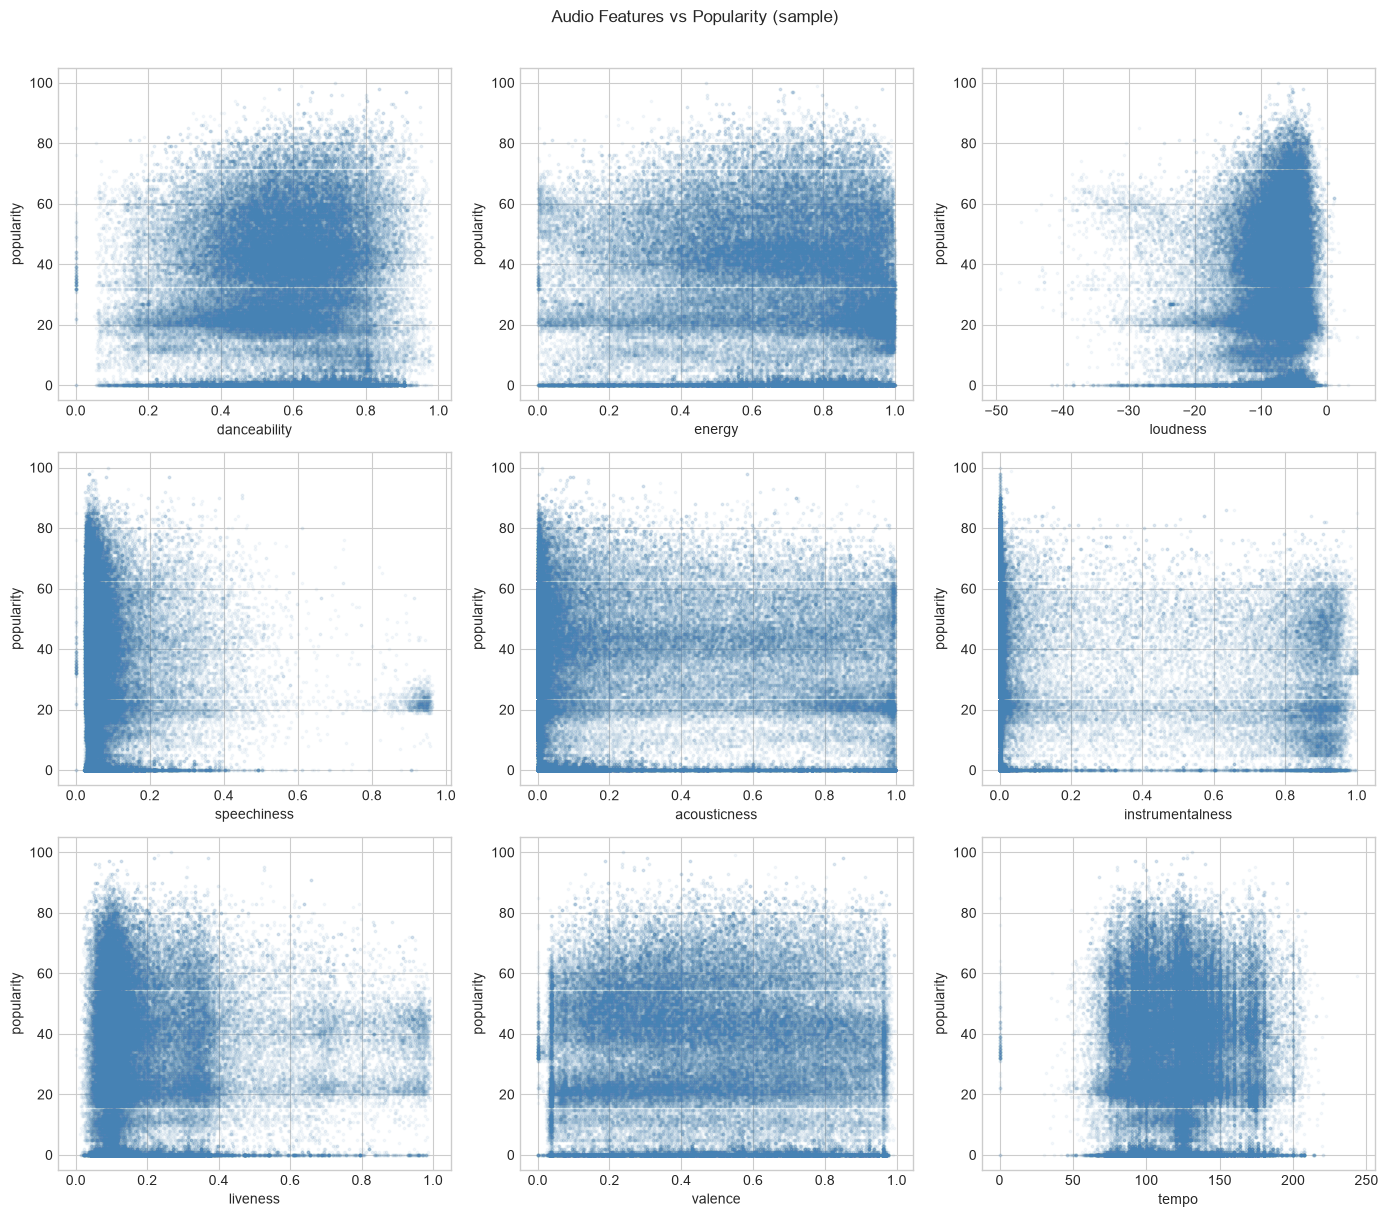

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, feat in zip(axes.flat, audio_features):
    ax.scatter(df[feat], df['popularity'], alpha=0.05, s=3, color='steelblue')
    ax.set_xlabel(feat)
    ax.set_ylabel('popularity')
plt.suptitle('Audio Features vs Popularity (sample)', y=1.01)
plt.tight_layout()
plt.show()

## 3. Feature Engineering & Preprocessing

In [ ]:
# Drop rows with missing text fields (only 1 row)
df_clean = df.dropna(subset=['artists', 'album_name', 'track_name']).copy()

# Engineered features
df_clean['explicit'] = df_clean['explicit'].astype(int)
df_clean['duration_min'] = df_clean['duration_ms'] / 60_000
df_clean['num_artists'] = df_clean['artists'].str.count(';') + 1

NUMERIC_FEATURES = [
    'duration_min', 'explicit', 'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'time_signature', 'num_artists'
]
CATEGORICAL_FEATURES = ['track_genre']
TARGET = 'popularity'

X = df_clean[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df_clean[TARGET]

print(f'Features: {len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical')
print(f'Training samples: {len(X):,}')

Features: 15 numeric + 1 categorical
Training samples: 113,999


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ('num', 'passthrough', NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])

print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')

Train: 91,199 | Test: 22,800


## 4. Model Training & Comparison

We train **5 models** spanning linear and tree-based approaches, then pick the one with the lowest test RMSE:

| # | Model | Type |
|---|---|---|
| 1 | Ridge Regression | Linear baseline |
| 2 | Random Forest | Bagging ensemble |
| 3 | HistGradientBoosting | Sklearn gradient boosting |
| 4 | XGBoost | Optimised gradient boosting |
| 5 | LightGBM | Leaf-wise gradient boosting |

In [ ]:
def evaluate_model(name, pipeline, X_train, y_train, X_test, y_test):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    cv_scores = cross_val_score(
        pipeline, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    cv_rmse = -cv_scores.mean()

    return {
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2,
        'CV RMSE (5-fold)': cv_rmse,
        'pipeline': pipeline,
        'y_pred': y_pred,
    }

In [ ]:
models = {
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        max_iter=200, max_depth=8, learning_rate=0.1, random_state=RANDOM_STATE
    ),
    'XGBoost': XGBRegressor(
        n_estimators=200, max_depth=8, learning_rate=0.1,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=200, max_depth=8, learning_rate=0.1,
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    ),
}

results = []
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    print(f'Training {name}...')
    result = evaluate_model(name, pipe, X_train, y_train, X_test, y_test)
    results.append(result)
    print(f'  RMSE={result["RMSE"]:.2f}  MAE={result["MAE"]:.2f}  R²={result["R²"]:.4f}  CV RMSE={result["CV RMSE (5-fold)"]:.2f}\n')

Training Ridge Regression...
  RMSE=19.14  MAE=14.09  R²=0.2617  CV RMSE=19.24

Training Random Forest...
  RMSE=15.25  MAE=10.27  R²=0.5313  CV RMSE=15.78

Training HistGradientBoosting...
  RMSE=18.12  MAE=13.38  R²=0.3382  CV RMSE=18.18

Training XGBoost...
  RMSE=17.85  MAE=13.08  R²=0.3577  CV RMSE=18.00

Training LightGBM...
  RMSE=18.08  MAE=13.35  R²=0.3411  CV RMSE=18.17



In [ ]:
comparison = pd.DataFrame(results)[['Model', 'RMSE', 'MAE', 'R²', 'CV RMSE (5-fold)']]
comparison = comparison.sort_values('RMSE')
# comparison.style.highlight_min(subset=['RMSE', 'MAE', 'CV RMSE (5-fold)'], color='lightgreen')\
#                      .highlight_max(subset=['R²'], color='lightgreen')

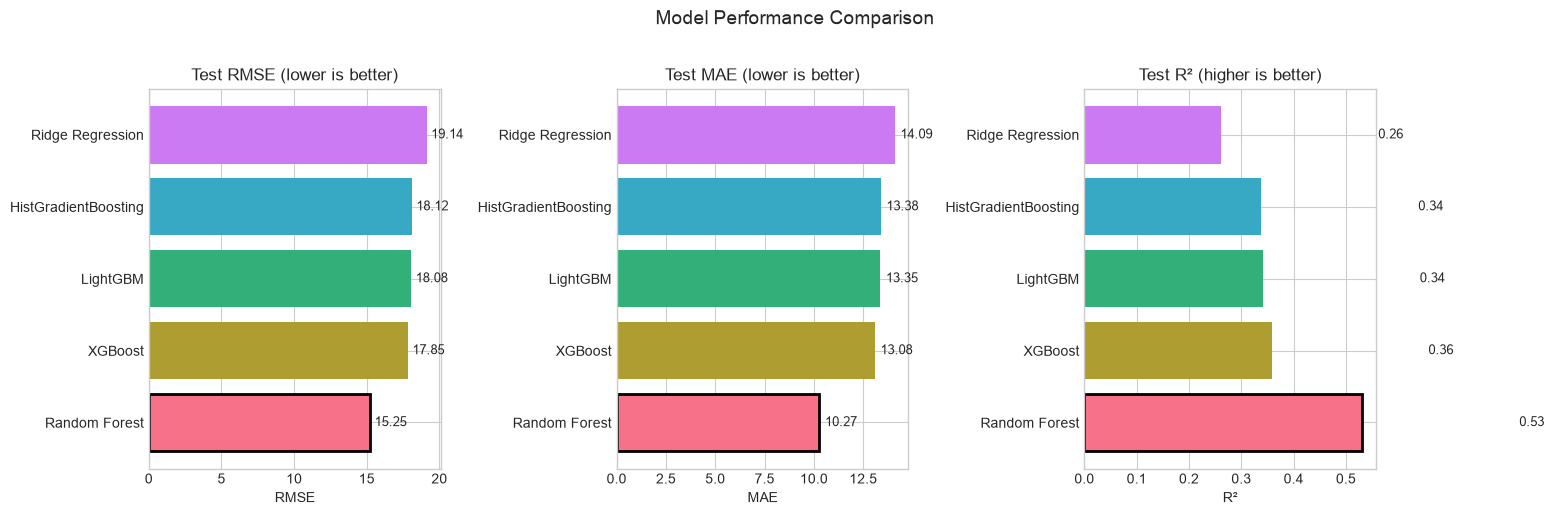

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
comparison_sorted = comparison.sort_values('RMSE')

colors = sns.color_palette('husl', len(comparison_sorted))
for ax, metric, title in zip(
    axes,
    ['RMSE', 'MAE', 'R²'],
    ['Test RMSE (lower is better)', 'Test MAE (lower is better)', 'Test R² (higher is better)']
):
    bars = ax.barh(comparison_sorted['Model'], comparison_sorted[metric], color=colors)
    ax.set_title(title)
    ax.set_xlabel(metric)
    # Highlight best bar
    best_idx = 0 if metric != 'R²' else comparison_sorted[metric].values.argmax()
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2)
    for bar, val in zip(bars, comparison_sorted[metric]):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                f'{val:.2f}', va='center', fontsize=9)

plt.suptitle('Model Performance Comparison', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 5. Best Model Evaluation

In [ ]:
best = min(results, key=lambda r: r['RMSE'])
best_model = best['pipeline']
y_pred = best['y_pred']

print(f'Best model: {best["Model"]}')
print(f'Test RMSE: {best["RMSE"]:.2f}  (popularity is 0–100 scale)')
print(f'Test MAE:  {best["MAE"]:.2f}')
print(f'Test R²:   {best["R²"]:.4f}')

Best model: Random Forest
Test RMSE: 15.25  (popularity is 0–100 scale)
Test MAE:  10.27
Test R²:   0.5313


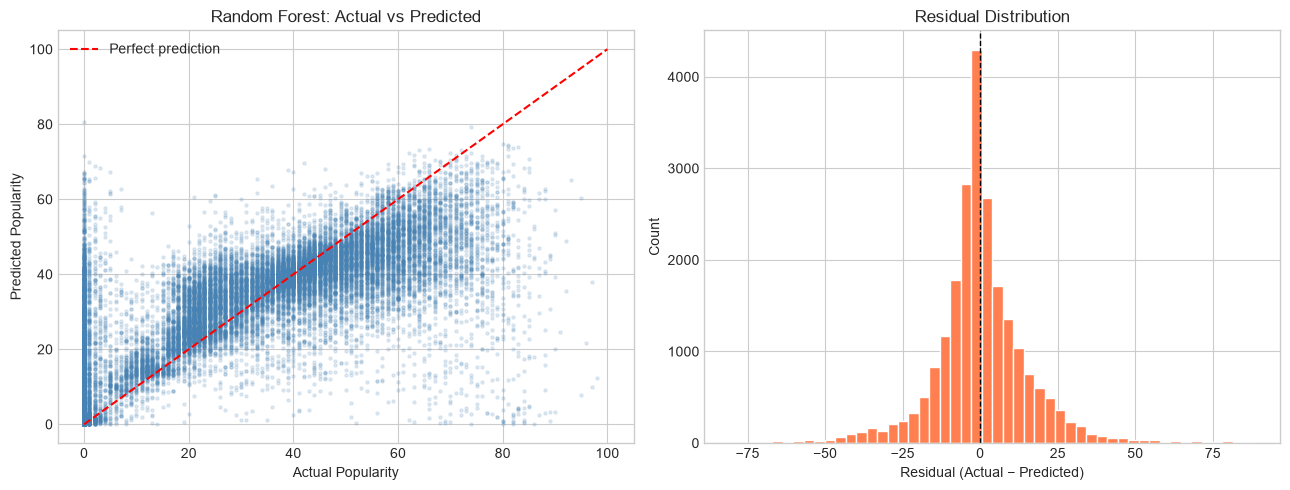

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.15, s=5, color='steelblue')
axes[0].plot([0, 100], [0, 100], 'r--', lw=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual Popularity')
axes[0].set_ylabel('Predicted Popularity')
axes[0].set_title(f'{best["Model"]}: Actual vs Predicted')
axes[0].legend()

# Residuals
residuals = y_test.values - y_pred
axes[1].hist(residuals, bins=50, edgecolor='white', color='coral')
axes[1].axvline(0, color='black', linestyle='--', lw=1)
axes[1].set_xlabel('Residual (Actual − Predicted)')
axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution')

plt.tight_layout()
plt.show()

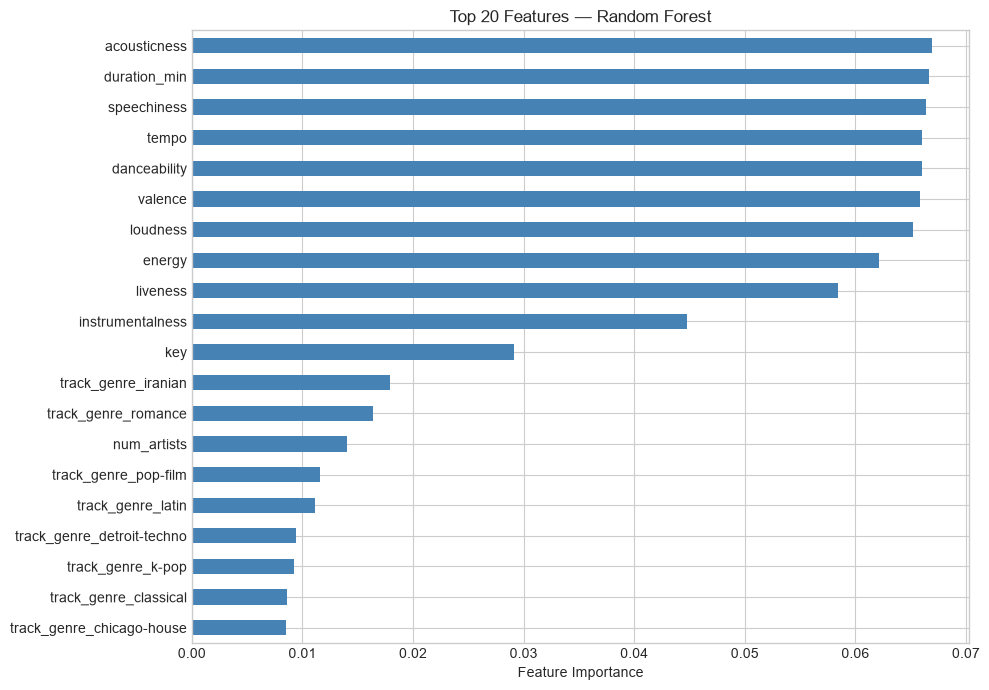

In [ ]:
def get_feature_names(preprocessor, numeric_features, categorical_features):
    ohe = preprocessor.named_transformers_['cat']
    cat_names = ohe.get_feature_names_out(categorical_features)
    return list(numeric_features) + list(cat_names)

tree_model = best_model.named_steps['model']
if hasattr(tree_model, 'feature_importances_'):
    feature_names = get_feature_names(
        best_model.named_steps['prep'], NUMERIC_FEATURES, CATEGORICAL_FEATURES
    )
    importances = pd.Series(tree_model.feature_importances_, index=feature_names)
    top_features = importances.sort_values(ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(10, 7))
    top_features.sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_xlabel('Feature Importance')
    ax.set_title(f'Top 20 Features — {best["Model"]}')
    plt.tight_layout()
    plt.show()
else:
    print(f'{best["Model"]} does not expose feature importances.')

## 6. Sample Predictions

In [ ]:
sample_idx = y_test.sample(10, random_state=RANDOM_STATE).index
sample_df = df_clean.loc[sample_idx, ['track_name', 'artists', 'track_genre', 'popularity']].copy()
sample_df['predicted_popularity'] = best_model.predict(X.loc[sample_idx]).round(1)
sample_df['error'] = (sample_df['popularity'] - sample_df['predicted_popularity']).round(1)
sample_df

,track_name,artists,track_genre,popularity,predicted_popularity,error
23342,Silent,Embody,deep-house,50,41.0,9.0
56496,Holiday Rock,Neon Trees,indie-pop,0,0.3,-0.3
30524,Ping Pong - Hardwell Remix,Armin van Buuren;Hardwell,edm,55,48.2,6.8
104552,"Marta, Sebas, Guille y los demás",Amaral,spanish,60,39.9,20.1
96875,Conto De Fadas,Negritude Junior,samba,36,35.2,0.8
101047,Weißes Rauschen: Baby Schlafhelfer,Weißes Rauschen HD,sleep,52,36.6,15.4
113885,Wouldn't It Be Like You - Live,Bryan & Katie Torwalt,world-music,23,43.2,-20.2
62149,Let It Snow,Diana Krall;Clayton-Hamilton Jazz Orchestra,j-pop,0,18.5,-18.5
41207,The Reckoning,Within Temptation;Jacoby Shaddix,goth,53,31.7,21.3
5604,イザベラの唄 (Mandolin Version),小畑貴裕,anime,47,44.6,2.4
